In [3]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [21]:
class BatsmanState(TypedDict):
    runs:int
    balls:int
    fours:int
    sixes:int
    
    strikeRate:float
    boundryPerBall:float
    boundryPercentage:float
    summary:str

In [22]:
def calculate_strikeRate(state:BatsmanState)-> BatsmanState:
    strikeRate= (state['runs']/state['balls'])* 100
    
    return {'strikeRate':strikeRate}

In [23]:
def calculate_bpb(state: BatsmanState)->BatsmanState:
    boundryPerBall= state['balls']/(state['fours']+state['sixes'])
    
    return {'boundryPerBall':boundryPerBall}
    

In [24]:
def calculate_boundry_percentage(state:BatsmanState)->BatsmanState:
    boundryPercentage= ((state['fours']*4 + state['sixes']*6)/state['runs'])*100

    return {'boundryPercentage':boundryPercentage}
    

In [40]:
def summary(state:BatsmanState)->BatsmanState:
    summary_ret = f"""Batsman Summary:
    Runs: {state['runs']}
    Balls: {state['balls']}
    Fours: {state['fours']}
    Sixes: {state['sixes']}
    Strike Rate: {state['strikeRate']}
    Boundaries per Ball: {state['boundryPerBall']}
    Boundary Percentage: {state['boundryPercentage']}
    """
    
    return {'summary':summary_ret}

In [41]:
graph =StateGraph(BatsmanState)
graph.add_node("calculate_strikeRate", calculate_strikeRate)
graph.add_node("calculate_bpb", calculate_bpb)
graph.add_node("calculate_boundary_percentage", calculate_boundry_percentage)
graph.add_node("summary",summary)

graph.add_edge(START, "calculate_strikeRate")
graph.add_edge(START, "calculate_bpb")
graph.add_edge(START, "calculate_boundary_percentage")

graph.add_edge("calculate_strikeRate", "summary")
graph.add_edge("calculate_bpb", "summary")
graph.add_edge("calculate_boundary_percentage", "summary")

graph.add_edge("summary", END)

workflow= graph.compile()

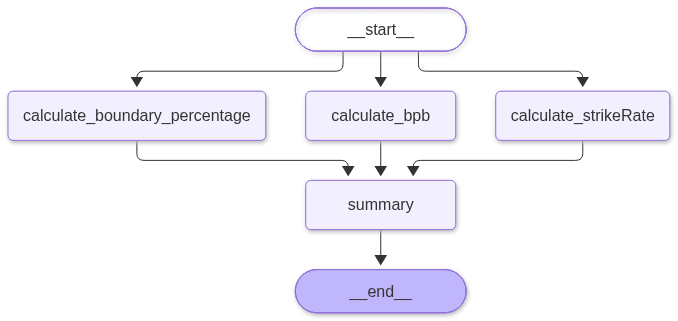

In [42]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())


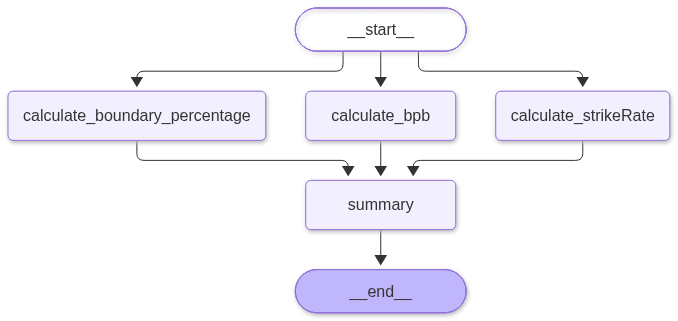

In [43]:
workflow

In [44]:
initial_state={"runs":100,"balls":50,"fours":6,"sixes":4}
final_state=workflow.invoke(initial_state)
print(final_state)

{'runs': 100, 'balls': 50, 'fours': 6, 'sixes': 4, 'strikeRate': 200.0, 'boundryPerBall': 5.0, 'boundryPercentage': 48.0, 'summary': 'Batsman Summary:\n    Runs: 100\n    Balls: 50\n    Fours: 6\n    Sixes: 4\n    Strike Rate: 200.0\n    Boundaries per Ball: 5.0\n    Boundary Percentage: 48.0\n    '}
